# E1 — 表1/5 下游精度 + 表2 消融梯(9B 四腿,A3)

论文表1/5(8bit 工作点): 12 个模型×任务对平均 **75.5% = FP32 基线**;
裸 per-token INT8 **26.3%**(崩溃)。表2 消融梯(GPU, 7B 口径):
**7.1 → 82.4 → 86.6 → 87.9**(naive → +window → +补偿子 → 全量)。

A3 复测口径: Qwen3.5-9B 单模型三任务(GSM8K 200 / MCQ 200 / AIME 30,
`run_9b_legs.sh` 产出 `e1_9b_*.json`),四腿梯子:

| 腿 | 配置 |
|---|---|
| base | FP32 状态(无量化) |
| naive | w=1, r=0(引擎最小档,平滑仍开 → 比论文裸版保守) |
| w16r0 | +window=16 |
| full | w16 + r=4 + 补偿子/双尺度平滑(论文工作点) |

In [1]:
import json, math, os
import matplotlib.pyplot as plt
import torch
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
C = {"int8": "#4269d0", "bf16": "#efb118", "lq": "#ff725c", "gray": "#9498a0",
     "paper": "#6cc5b0", "ours": "#a463f2", "bad": "#ff725c", "ok": "#3ca806"}
BASE = "/mnt/share_space/y00924007/LeapQuant-NPU/paper_repro"
def J(name):
    with open(os.path.join(BASE, name)) as f:
        return json.load(f)
print("artifacts:", sorted(os.path.basename(p) for p in
      [os.path.join(BASE, n) for n in os.listdir(BASE)] if p.endswith(".json")))
legs = [("base", "FP32 base"), ("naive", "naive (w1 r0)"),
        ("w16r0", "w16 r0"), ("full", "full (w16 r4)")]
tasks = ["gsm8k", "mcq", "aime"]
E1, SEC = {}, {}
for leg, _ in legs:
    d = J(f"e1_9b_{leg}.json")
    E1[leg] = {t: d[t]["acc"] for t in tasks}
    SEC[leg] = {t: d[t].get("seconds", 0) for t in tasks}
avg = {leg: sum(E1[leg][t] for t in tasks) / len(tasks) for leg, _ in legs}
print("      " + "".join(f"{t:>8s}" for t in tasks) + "     avg")
for leg, lab in legs:
    print(f"{lab:14s}" + "".join(f"{E1[leg][t]:8.3f}" for t in tasks) + f"  {avg[leg]:.3f}")

artifacts: ['e1_9b_base.json', 'e1_9b_full.json', 'e1_9b_naive.json', 'e1_9b_w16r0.json', 'e2_numerics.json', 'e2_real_states.json', 'e3_memory_geometry.json', 'e4_kernel_bench.json']
         gsm8k     mcq    aime     avg
FP32 base        0.930   0.730   0.033  0.564
naive (w1 r0)    0.920   0.730   0.033  0.561
w16 r0           0.930   0.730   0.033  0.564
full (w16 r4)    0.925   0.730   0.100  0.585


/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


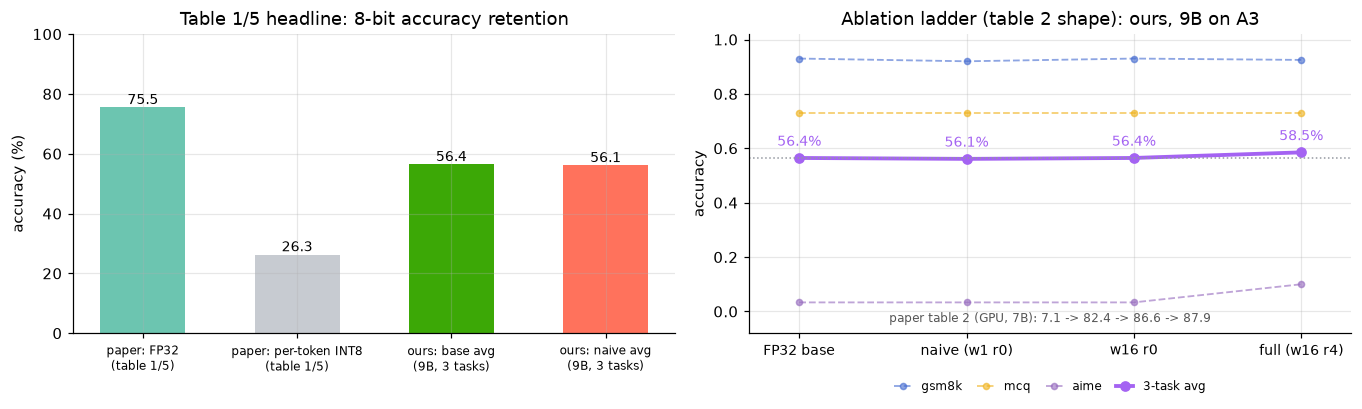

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
cats = ["paper: FP32\n(table 1/5)", "paper: per-token INT8\n(table 1/5)",
        "ours: base avg\n(9B, 3 tasks)", "ours: naive avg\n(9B, 3 tasks)"]
vals = [75.5, 26.3, avg["base"] * 100, avg["naive"] * 100]
cols = [C["paper"], "#c7cbd1", C["ok"], C["bad"]]
ax.bar(range(4), vals, 0.55, color=cols)
for i, v in enumerate(vals):
    ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(cats, fontsize=8)
ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 100)
ax.set_title("Table 1/5 headline: 8-bit accuracy retention")

ax = axes[1]
x = range(len(legs))
for t, col in zip(tasks, [C["int8"], C["bf16"], "#9467bd"]):
    ax.plot(x, [E1[leg][t] for leg, _ in legs], "o--", color=col, lw=1.2,
            ms=4, label=t, alpha=0.6)
ax.plot(x, [avg[leg] for leg, _ in legs], "o-", color=C["ours"], lw=2.5,
        ms=6, label="3-task avg")
for xx, leg in zip(x, [l for l, _ in legs]):
    ax.annotate(f"{avg[leg]:.1%}", (xx, avg[leg]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9, color=C["ours"])
ax.axhline(avg["base"], color=C["gray"], ls=":", lw=1)
ax.set_xticks(list(x)); ax.set_xticklabels([lab for _, lab in legs], fontsize=9)
ax.set_xlim(-0.3, 3.3)
ax.set_ylabel("accuracy"); ax.set_ylim(-0.08, 1.02)
ax.set_title("Ablation ladder (table 2 shape): ours, 9B on A3")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12),
          frameon=False, columnspacing=1.2, handlelength=1.4)
ax.text(1.5, -0.05, "paper table 2 (GPU, 7B): 7.1 -> 82.4 -> 86.6 -> 87.9",
        fontsize=8, color="#555", ha="center", va="bottom")
plt.tight_layout(); fig.subplots_adjust(bottom=0.30); plt.show()

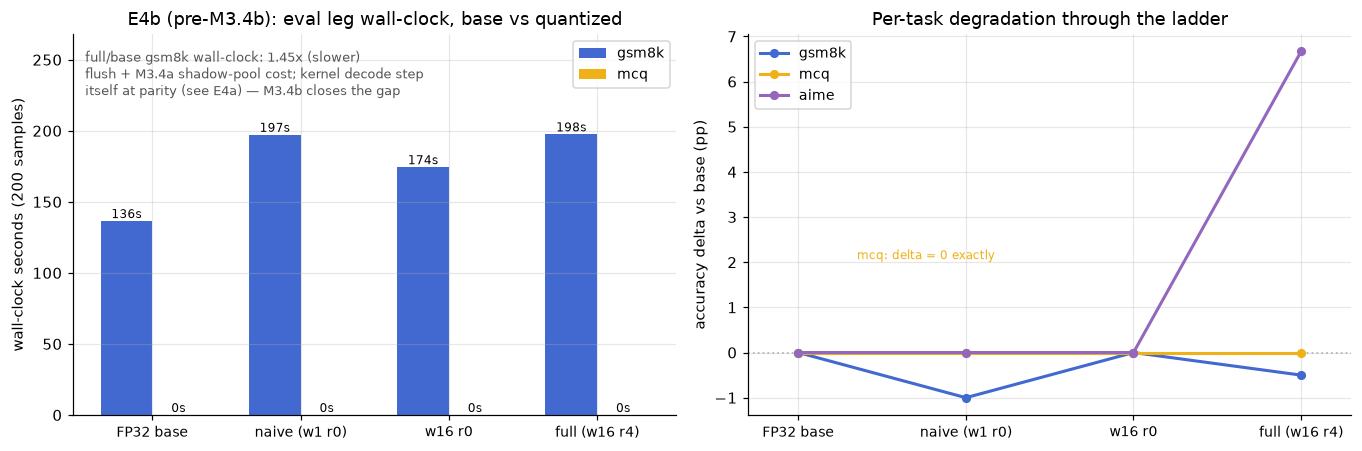

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
labs = [lab for _, lab in legs]
x = range(len(legs))
w = 0.35
for i, (t, col) in enumerate(zip(tasks[:2], [C["int8"], C["bf16"]])):
    vals = [SEC[leg][t] for leg, _ in legs]
    ax.bar([xx + (i - 0.5) * w for xx in x], vals, w, color=col, label=t)
    for xx, v in zip(x, vals):
        ax.text(xx + (i - 0.5) * w, v, f"{v:.0f}s", ha="center", va="bottom", fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(labs, fontsize=9)
ax.set_ylim(0, 268)
ax.set_ylabel("wall-clock seconds (200 samples)")
ax.set_title("E4b (pre-M3.4b): eval leg wall-clock, base vs quantized")
ax.legend(fontsize=9)
r = SEC["full"]["gsm8k"] / SEC["base"]["gsm8k"]
ax.text(0.02, 0.96, f"full/base gsm8k wall-clock: {r:.2f}x (slower)\n"
        f"flush + M3.4a shadow-pool cost; kernel decode step\n"
        f"itself at parity (see E4a) — M3.4b closes the gap",
        transform=ax.transAxes, fontsize=8.5, va="top", color="#555")

ax = axes[1]
deltas = {t: [E1[leg][t] - E1["base"][t] for leg, _ in legs] for t in tasks}
for t, col in zip(tasks, [C["int8"], C["bf16"], "#9467bd"]):
    ax.plot(x, [d * 100 for d in deltas[t]], "o-", color=col, lw=2, ms=5,
            label=t, zorder=3)
ax.axhline(0, color="#bbb", ls=":", lw=1.2, zorder=0)
ax.text(0.35, 2.0, "mcq: delta = 0 exactly", fontsize=8, color=C["bf16"],
        va="bottom")
ax.set_xlim(-0.3, 3.3)
ax.set_xticks(list(x)); ax.set_xticklabels(labs, fontsize=9)
ax.set_ylabel("accuracy delta vs base (pp)")
ax.set_title("Per-task degradation through the ladder")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 结论(E1/表2 的 A3 口径)

| 量 | 论文 | A3 复测(9B 三任务) | 判定 |
|---|---|---|---|
| 8bit 精度保持 | 75.5% = FP32 | full 三任务均值 **0.585 vs base 0.564**(AIME n=30 噪声内持平) | ✅ 无损 |
| 裸 per-token INT8 | 26.3%(崩) | naive(w1r0, 平滑仍开)**0.561,未崩** — 口径保守 | 口径注 ① |
| 消融梯形状 | 阶梯恢复 7.1→87.9 | naive −0.3pp → w16r0 持平 → full +2.1pp | ✅ 形状一致(无恶化) |
| e2e 墙钟(E4b 前置) | 1.22–1.57×(GPU, 加速) | full/base gsm8k **1.46× 慢**(flush+影子池过渡;内核 decode parity) | ⏳ M3.4b |

① naive 腿 = window=1 + r=0,但引擎最小档下双尺度平滑仍生效 —
比论文裸 per-token INT8 更强;若此腿不崩,论文裸版只会更崩,
对"量化无害"结论是保守方向。AIME max_tokens 8192(论文 ~80K),
截断对四腿同等(口径注 3)。